In [1]:
#Load packages
import warnings
warnings.filterwarnings("ignore")
from watermark import watermark

#file operating
import json
import os
import os.path
import re
import sys
import cv2
from functools import reduce

#data processing platform
import anndata as ad
import geopandas as gpd
import numpy as np
import pandas as pd
import spatialdata as sd
import squidpy as sq
import spatialdata_plot
import scanpy as sc
from affine import Affine
from collections import Counter
from shapely import affinity
from rasterio.features import rasterize
from scipy.ndimage import binary_dilation
from shapely.geometry import Polygon
from spatialdata import bounding_box_query
from spatialdata.models import ShapesModel, Labels2DModel
from spatialdata.models import Image2DModel 
from spatialdata.transformations import Scale
from spatialdata.transformations import get_transformation, set_transformation, Affine, Identity, Sequence

#plotting
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

In [2]:
%load_ext watermark

In [3]:
#folder/ file setup based on your project
sourcefiles = "/stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/source_files"
zarrfiles = "/stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/zarr_files"
outputfiles = "/stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/derived_files/"
imageannotationfiles = "/stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations"

functiondirs = "/host_root/nethome/reny28/Projects/Custom_functions/python_functions"

In [3]:
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.ops import unary_union
from shapely.geometry import box
import spatialdata as sd  # make sure you `import spatialdata as sd`

def assign_annotations_fast(
    sdata,
    annotation_names=["Tissue", "Anthropotic", "Necrosis"],
    annot_shapes_key="annotations_raw",
    table_key="square_002um",
    visium_name="Visium_area",                 # if not present, we fall back to the grid bounds
    target_coordinate_system="global",
    store_as="bool",                           # "bool" or "category"
):
    """
    Speedups:
      • crop to Visium area once
      • union polygons per class
      • use clip=False (membership only)
    """
    # --- 0) grab the annotations GeoDataFrame
    ann_gdf = gpd.GeoDataFrame(sdata.shapes[annot_shapes_key]).copy()

    # --- 1) build the Visium region polygon
    vis_rows = ann_gdf.loc[ann_gdf["name"].astype(str) == visium_name, "geometry"]
    if len(vis_rows):
        vis_poly = unary_union(vis_rows.values)
    else:
        # fallback: tight bbox over the squares shapes element
        grid_key = next(k for k in sdata.shapes.keys() if "square_002um" in k)
        grid_gdf = gpd.GeoDataFrame(sdata.shapes[grid_key])
        minx, miny, maxx, maxy = grid_gdf.total_bounds
        vis_poly = box(minx, miny, maxx, maxy)

    # --- 2) crop once to Visium area (fast membership, no clipping)
    sdata_vis = sd.polygon_query(
        sdata, polygon=vis_poly, target_coordinate_system=target_coordinate_system, clip=False
    )

    # We'll write into the original table; indices are the same
    adata = sdata.tables[table_key]

    # initialize destination columns
    if store_as == "bool":
        for a in annotation_names:
            col = f"is_{a}"
            if col not in adata.obs:
                adata.obs[col] = False
    elif store_as == "category":
        for a in annotation_names:
            if a not in adata.obs:
                adata.obs[a] = pd.Categorical.from_codes(
                    np.zeros(adata.n_obs, dtype=np.int8), categories=["unassigned", a]
                )
    else:
        raise ValueError("store_as must be 'bool' or 'category'.")

    # --- 3) union one polygon per annotation and query on the pre-cropped sdata
    for a in annotation_names:
        polys = ann_gdf.loc[ann_gdf["name"].astype(str) == a, "geometry"]
        if polys.empty:
            continue
        poly_union = unary_union(polys.values)

        # restrict the query area to Visium to avoid scanning off-slide
        roi = poly_union.intersection(vis_poly)
        if roi.is_empty:
            continue

        sub = sd.polygon_query(
            sdata_vis, polygon=roi, target_coordinate_system=target_coordinate_system, clip=False
        )
        idx = sub[table_key].obs.index  # rows of *your* main table that fall in this class

        if store_as == "bool":
            adata.obs.loc[idx, f"is_{a}"] = True
        else:
            adata.obs.loc[idx, a] = a

    # quick sanity counts
    if store_as == "bool":
        print({f"is_{a}": int(adata.obs[f"is_{a}"].sum()) for a in annotation_names})
    else:
        from collections import Counter
        print({a: Counter(adata.obs[a]) for a in annotation_names})

    return sdata  # modified in place

In [4]:
#load custom function
sys.path.append(functiondirs)
## to remove given string from a list of strings 
from cfs_202412 import remove_char, persist_changes, read_imagescope_annotation_xml, make_shapes_plot_safe
#
from cfs_202509 import macenko_normalize_visiumhd
# importantly, the pattern below is used to avoid the risk of losing
# the original table is this cell is killed while rewriting the original one
# this approach works for this notebook, but it other contexts, like with 
# network storages or multithread environment, it may not prevent data
# corruption. As a user, it is important to take this factors into 
# consideration and implement a strategy to minimize the risk of data loss.

In [5]:
#get sample names
zarrfiles_ls = os.listdir(zarrfiles)
sample_names = remove_char(zarrfiles_ls, ".zarr")
print(sample_names)

['Navli-82', 'Navli-84', 'Navli-86', 'Navli-80', 'Navli-59', 'Navli-81', 'Navli-85', 'Navli-62', 'Navli-60', 'Navli-41', 'Navli-45', 'Navli-46']


In [6]:
#load zarr files to a list
zarrfiles_ls = [sample_name + ".zarr" for sample_name in sample_names]
print(zarrfiles_ls)
zarrfiles_ls = [os.path.join(zarrfiles
                             , zarrfile_ls) for zarrfile_ls in zarrfiles_ls]
sdata_ls = [sd.SpatialData.read(zarrfile) for zarrfile in zarrfiles_ls]

['Navli-82.zarr', 'Navli-84.zarr', 'Navli-86.zarr', 'Navli-80.zarr', 'Navli-59.zarr', 'Navli-81.zarr', 'Navli-85.zarr', 'Navli-62.zarr', 'Navli-60.zarr', 'Navli-41.zarr', 'Navli-45.zarr', 'Navli-46.zarr']


In [7]:
#organzie data into dictionary
s_names = ["sample_" + sample_name for sample_name in sample_names]
sdata_ls = dict(zip(s_names, sdata_ls)) 
print(s_names)

['sample_Navli-82', 'sample_Navli-84', 'sample_Navli-86', 'sample_Navli-80', 'sample_Navli-59', 'sample_Navli-81', 'sample_Navli-85', 'sample_Navli-62', 'sample_Navli-60', 'sample_Navli-41', 'sample_Navli-45', 'sample_Navli-46']


In [8]:
#create a uniform color palette to consistency
all_cats = []
#load annotations and add to spatialdata object as "shapes"
for sdata_key in sdata_ls.keys():
    #load one annotation, this will be a polygon set 
    img_name = remove_char([sdata_key], "sample_")[0]
    #continue setup annotation path
    annotation_path = img_name + ".annotations"
    annotation_path = os.path.join(imageannotationfiles, annotation_path)
    report1 = "Now loading annotations from: " + annotation_path
    print(report1)
    annots_gdf_raw = read_imagescope_annotation_xml(annotation_path)#load files
    #create a set of names for corresponding elements used below
    img_name = img_name + "_hires_image"
    coord_name = "global"
    #isolate a single spatialdata object for convenience 
    sdata = sdata_ls[sdata_key]
    #annots_gdf_raw: polygons in pixel coordinates (as returned by read_imagescope_annotation_xml with no scaling)
    # 1) Parse the GeoDataFrame into a valid Shapes element (adds the internal attrs SpatialData needs)
    ann_raw = ShapesModel.parse(annots_gdf_raw)
    # 2) Reuse the morphology image’s transform (pixel -> global)
    #adjust "morphology" and "global" if your keys differ.
    #pix2glob = get_transformation(sdata.images[img_name], to_coordinate_system = coord_name) #no need to do if at scale
    # 3) Store the annotation in the shapes slot
    sdata.shapes["annotations_raw"] = ann_raw
    #pull the existing annotations, clean, and re-parse so that each polygon takes a unique row (essentially pivot_longer)
    ann_gdf_clean = make_shapes_plot_safe(ann_raw)
    ann_clean = ShapesModel.parse(ann_gdf_clean)
    #pull the shapes, normalize to str, and set Categorical dtype with an explicit order
    ann_clean["name"] = ann_clean["name"].astype(str)
    cats = pd.Index(sorted(ann_clean["name"].unique()))#the cats are created for each object and will be updated
    
    ann_clean["name"] = pd.Categorical(ann_clean["name"], categories=cats, ordered=True)
    sdata.shapes["annotations_clean"] = ann_clean
    
    #exprot all categories to the global cats (all_cats) 
    all_cats.append(cats.tolist())
    #return the spatialdata object to the dictionary
    sdata_ls[sdata_key] = sdata 
#flatten all cats and only keep unique elements
flatten = lambda *n: (e for a in n
    for e in (flatten(*a) if isinstance(a, (tuple, list)) else (a,)))
all_cats = list(flatten(all_cats))
all_cats = list(set(all_cats))
all_cats = sorted(all_cats)
del sdata #get rid of the duplicated large object in the end

Now loading annotations from: /stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations/Navli-82.annotations
Now loading annotations from: /stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations/Navli-84.annotations
Now loading annotations from: /stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations/Navli-86.annotations
Now loading annotations from: /stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations/Navli-80.annotations
Now loading annotations from: /stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations/Navli-59.annotations
Now loading annotations from: /stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations/Navli-81.annotations
Now loading annotations from: /stash/data/nonclin/TBIO-8106_VisiumHD-BMS504-mouseMC38/BMS504_VisiumHD_Annotations/Navli-85.annotations
Now loading annotations from: /stash/data/nonclin/TBIO-

In [9]:
#OPTIONAL: now comes the post annotation sanity check to see if the scale of the obsm["spatial"] 
#coordinates are compatible with our annotations
# This should be run earlier at the point the of annotation check.
# The aim for this is to check if annotation is at scale with the coordinates in .obsm['spatial'] slot.
for sdata_key in sdata_ls.keys():
    #again isolate a single spatialdata object for convenience 
    sdata = sdata_ls[sdata_key]
    #now let get the 4 cornners from the .obsm slot 
    xy_min = list(np.min(sdata["square_002um"].obsm['spatial'], axis=0))
    xy_max = list(np.max(sdata["square_002um"].obsm['spatial'], axis=0))
    minx, miny, maxx, maxy = list(xy_min + xy_max)
    visium_area = Polygon([(minx, miny), (minx, maxy), (maxx, maxy), (maxx, miny)])
    new_row_data = {'name': ['Visium_area'], 'visible': ['True'], 'linecolor': ['1772542'], 'geometry': [visium_area]}
    new_gdf_row = gpd.GeoDataFrame(new_row_data, crs=sdata['annotations_raw'].crs)
    #concatenate the new GeoDataFrame row with the existing GeoDataFrame
    new_gdf_raw = pd.concat([sdata.shapes['annotations_raw'], new_gdf_row], ignore_index=True)
    new_gdf_raw = ShapesModel.parse(new_gdf_raw)
    #cats = pd.Index(sorted(new_gdf_raw['name'].unique()))
    cats = sorted(new_gdf_raw['name'].unique())
    new_gdf_raw['name'] = pd.Categorical(new_gdf_raw['name'], categories=cats, ordered=True)# make sure the names are categorical
    sdata.shapes['annotations_raw'] = new_gdf_raw
    #now we update the "cat" to reflect the change
    all_cats.append(cats)
    #in order for us to see(plot) it we need to put it to the "pivotted" state
    ann_gdf_clean = make_shapes_plot_safe(sdata.shapes['annotations_raw'])
    ann_clean = ShapesModel.parse(ann_gdf_clean)
    ann_clean["name"] = ann_clean["name"].astype(str)
    ann_clean["name"] = pd.Categorical(ann_clean["name"], categories=cats, ordered=True)
    #re-inject the cleaned annotation to place
    sdata.shapes["annotations_clean"] = ann_clean
    #now that we are done, we return the
    sdata_ls[sdata_key] = sdata 
#flatten all cats and only keep unique elements
all_cats = list(flatten(all_cats))
all_cats = list(set(all_cats))
all_cats = sorted(all_cats)
del sdata #get rid of the duplicated large object in the end 

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


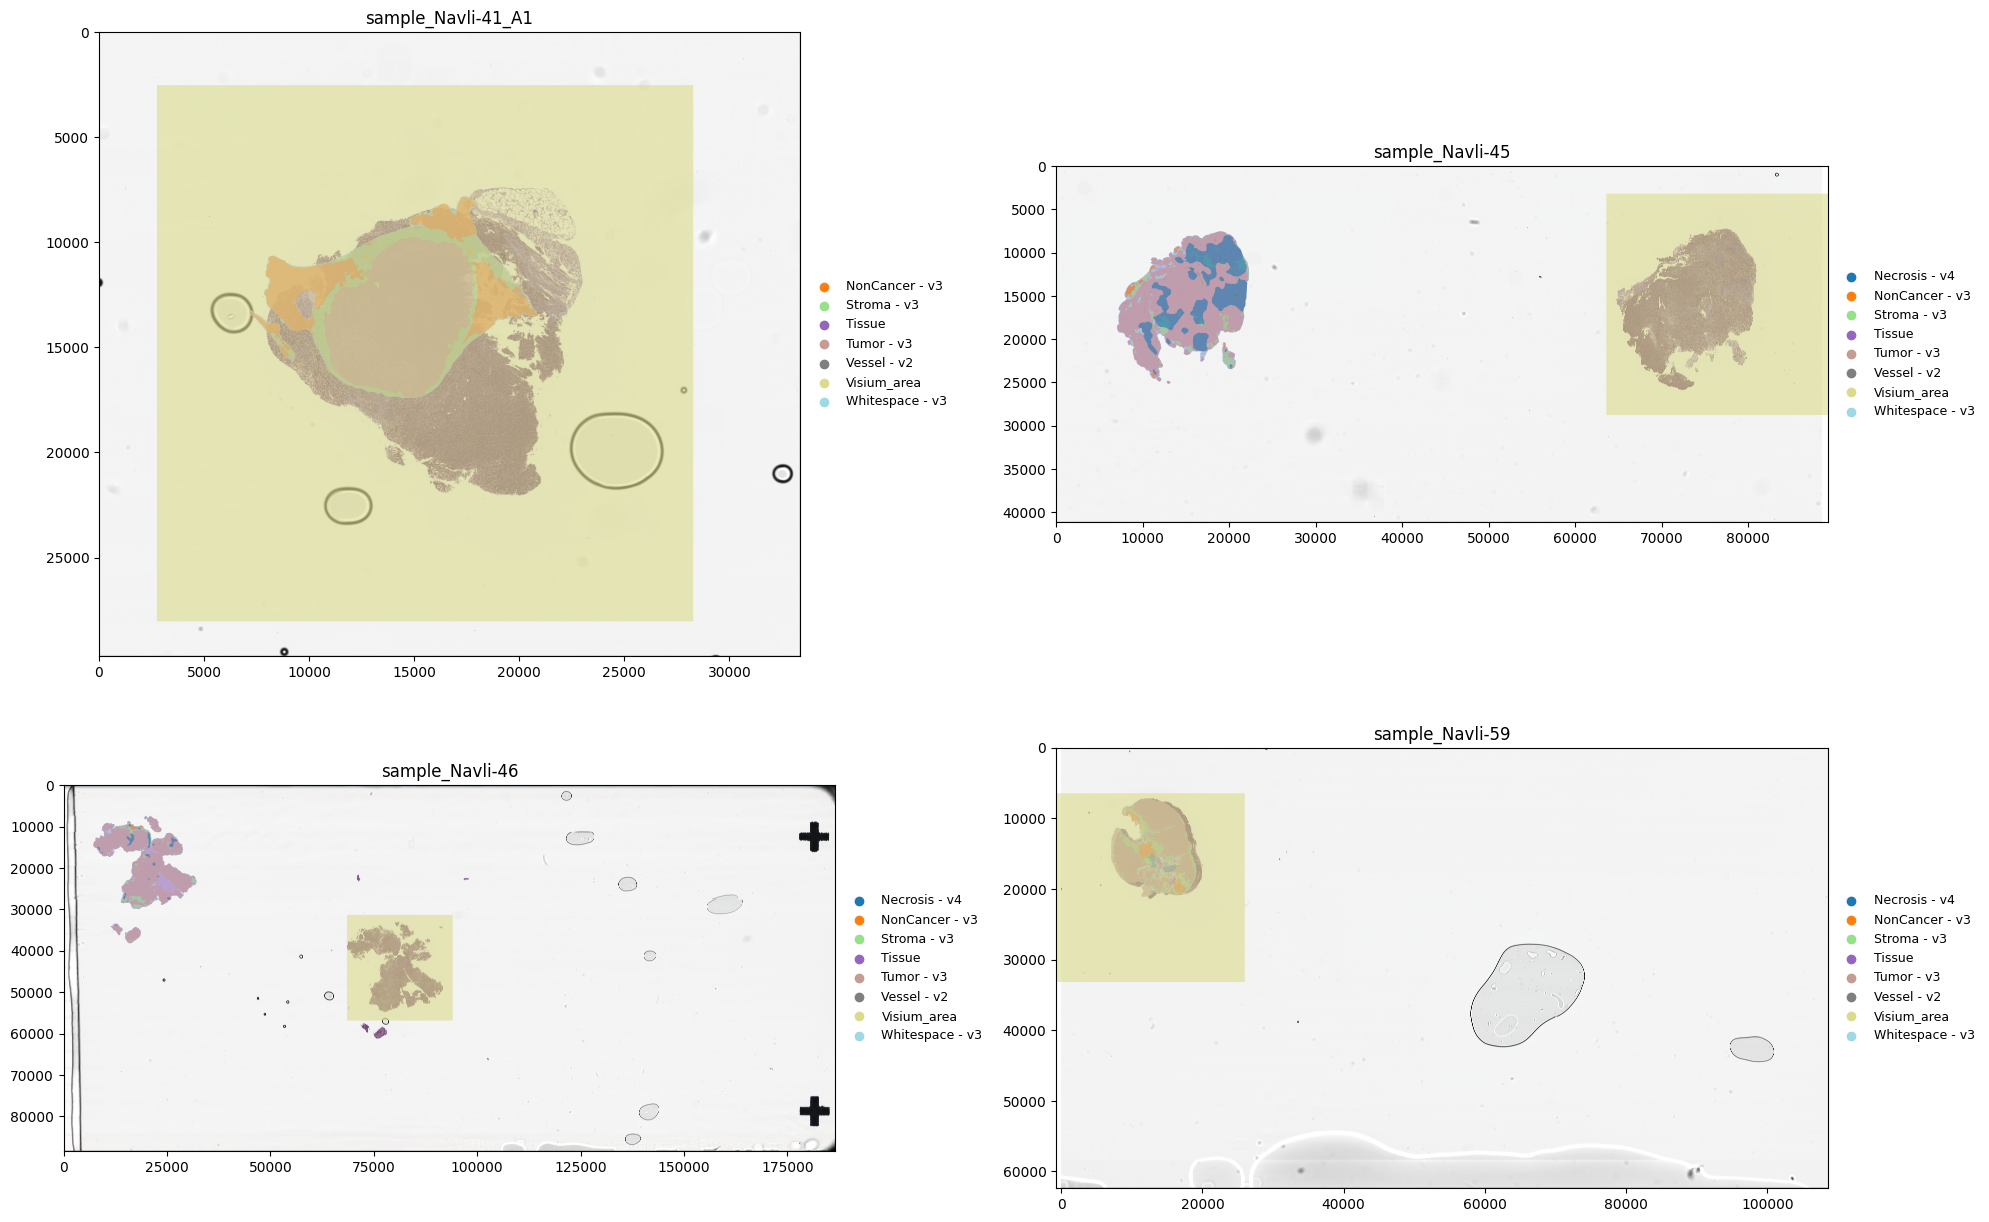

In [10]:
#preview plot for spatialdata object across all annotation classes
axes = plt.subplots(2, 2, figsize=(20, 13), dpi= 300)[1].flatten()
#preview shapes imported 
cmap = matplotlib.cm.get_cmap("tab20", len(all_cats))  # pick e.g. 'tab20', 'tab20b', 'tab20c', 'hsv'
palette_list = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(all_cats))]
#palette_list = pd.Series(palette_list, index=cats)
#['sample_BM0164135A_s1_A1', 'sample_BM0164126_s1_D1', 'sample_BM0164124A_s1_A1', 'sample_BM0164117_s1_D1']
#sample_Navli-41
sdata = sdata_ls['sample_Navli-41']
ax = (
    sdata.pl
        .render_images("Navli-41_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[0],
    title="sample_Navli-41_A1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-45
sdata = sdata_ls['sample_Navli-45']
ax = (
    sdata.pl
        .render_images("Navli-45_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[1],
    title="sample_Navli-45",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-46
sdata = sdata_ls['sample_Navli-46']
ax = (
    sdata.pl
        .render_images("Navli-46_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[2],
    title="sample_Navli-46",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-59
sdata = sdata_ls['sample_Navli-59']
ax = (
    sdata.pl
        .render_images("Navli-59_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[3],
    title="sample_Navli-59",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
plt.tight_layout()
del sdata

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


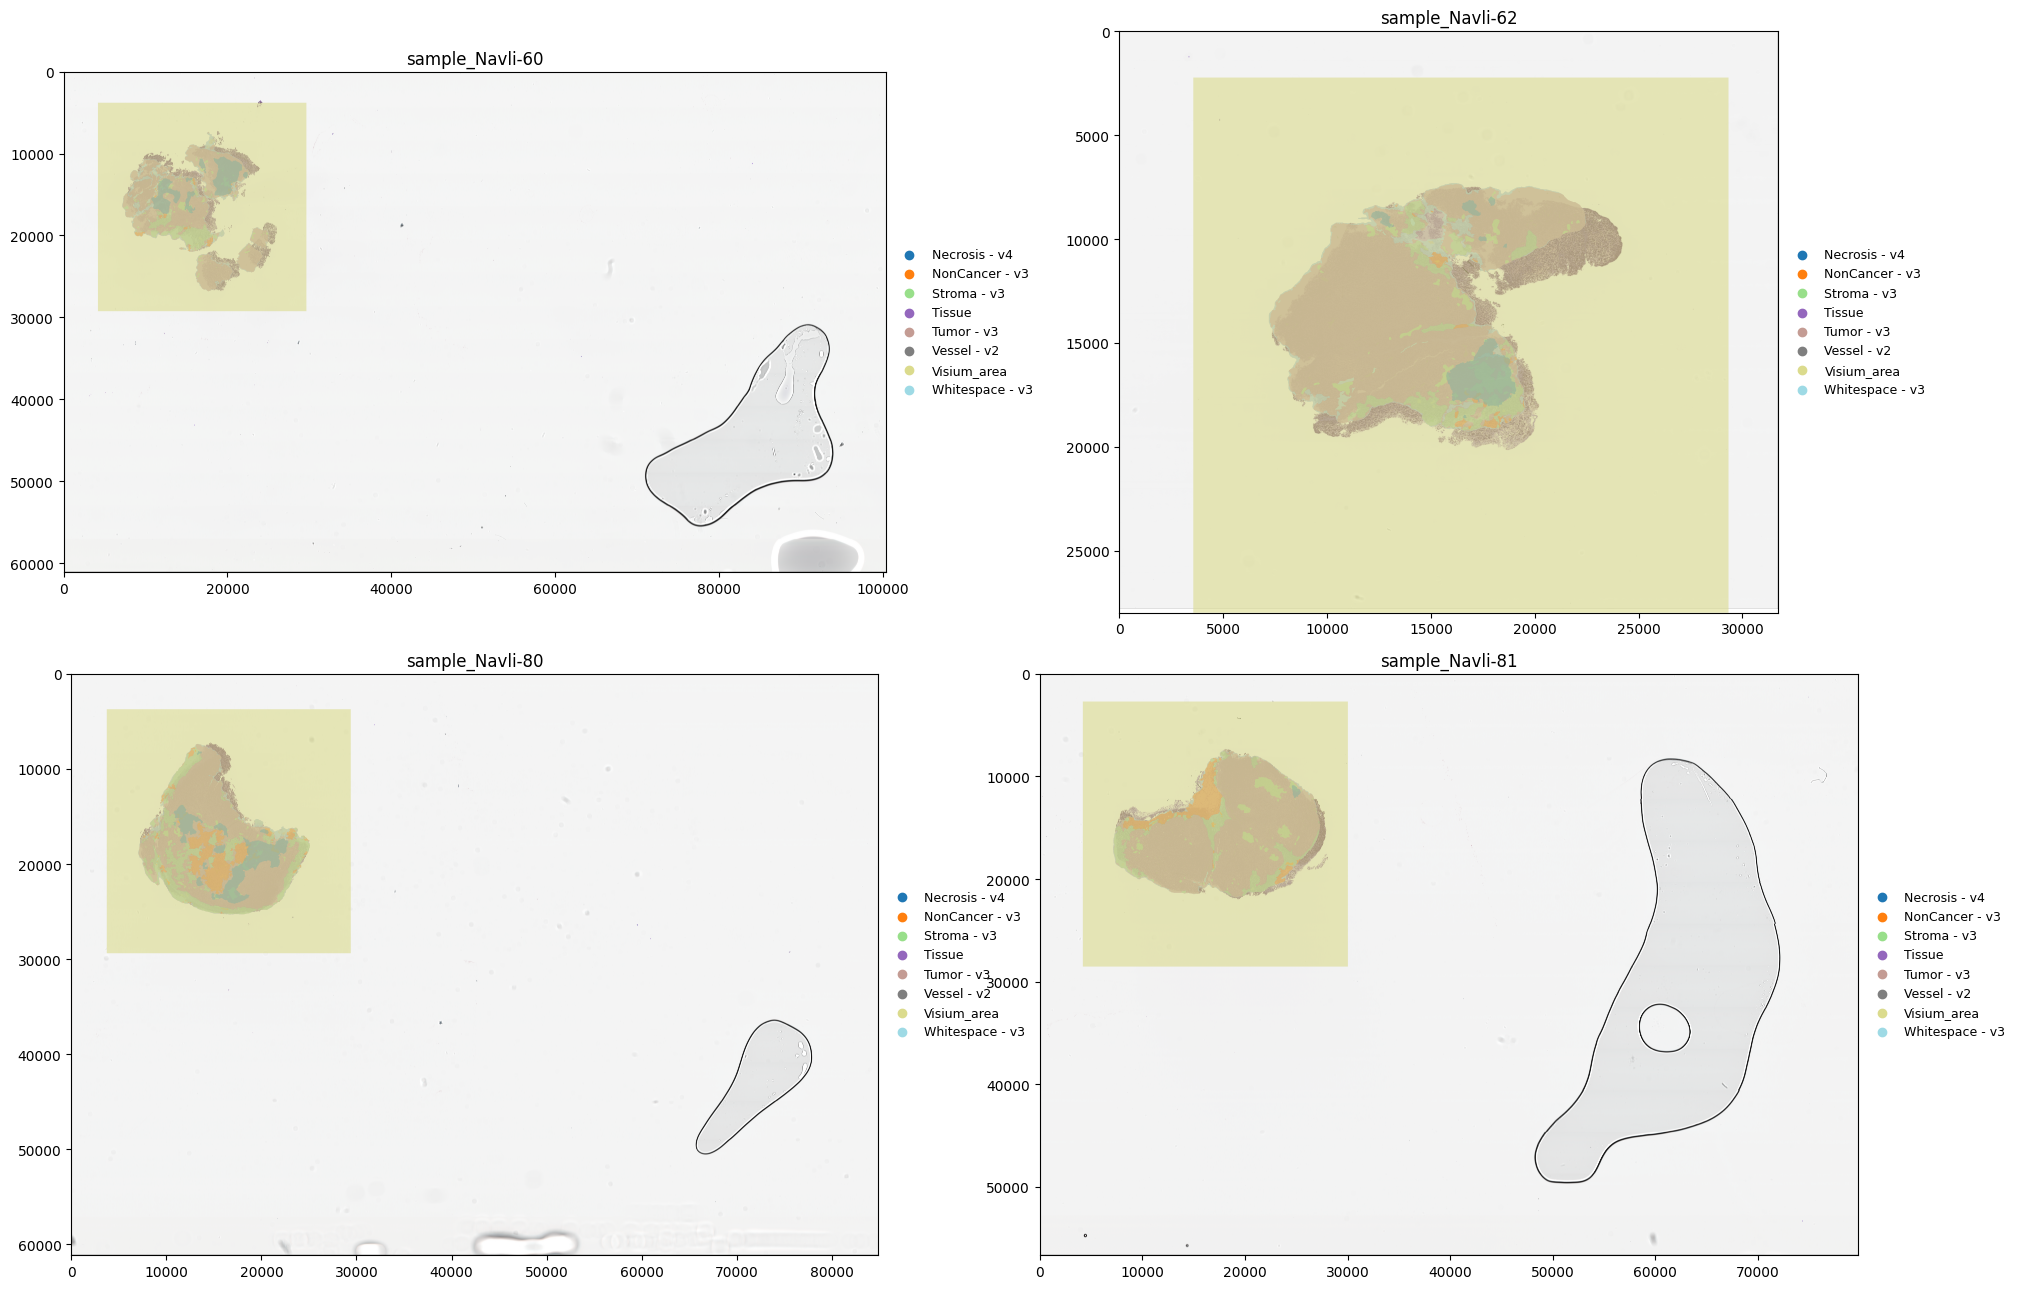

In [11]:
#preview plot for spatialdata object across all annotation classes
axes = plt.subplots(2, 2, figsize=(20, 13), dpi= 300)[1].flatten()
#preview shapes imported 
cmap = matplotlib.cm.get_cmap("tab20", len(all_cats))  # pick e.g. 'tab20', 'tab20b', 'tab20c', 'hsv'
palette_list = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(all_cats))]
#palette_list = pd.Series(palette_list, index=cats)
#['sample_BM0164135A_s1_A1', 'sample_BM0164126_s1_D1', 'sample_BM0164124A_s1_A1', 'sample_BM0164117_s1_D1']
#sample_Navli-60
sdata = sdata_ls['sample_Navli-60']
ax = (
    sdata.pl
        .render_images("Navli-60_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[0],
    title="sample_Navli-60",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-62
sdata = sdata_ls['sample_Navli-62']
ax = (
    sdata.pl
        .render_images("Navli-62_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[1],
    title="sample_Navli-62",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-80
sdata = sdata_ls['sample_Navli-80']
ax = (
    sdata.pl
        .render_images("Navli-80_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[2],
    title="sample_Navli-80",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-81
sdata = sdata_ls['sample_Navli-81']
ax = (
    sdata.pl
        .render_images("Navli-81_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[3],
    title="sample_Navli-81",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
plt.tight_layout()
del sdata

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


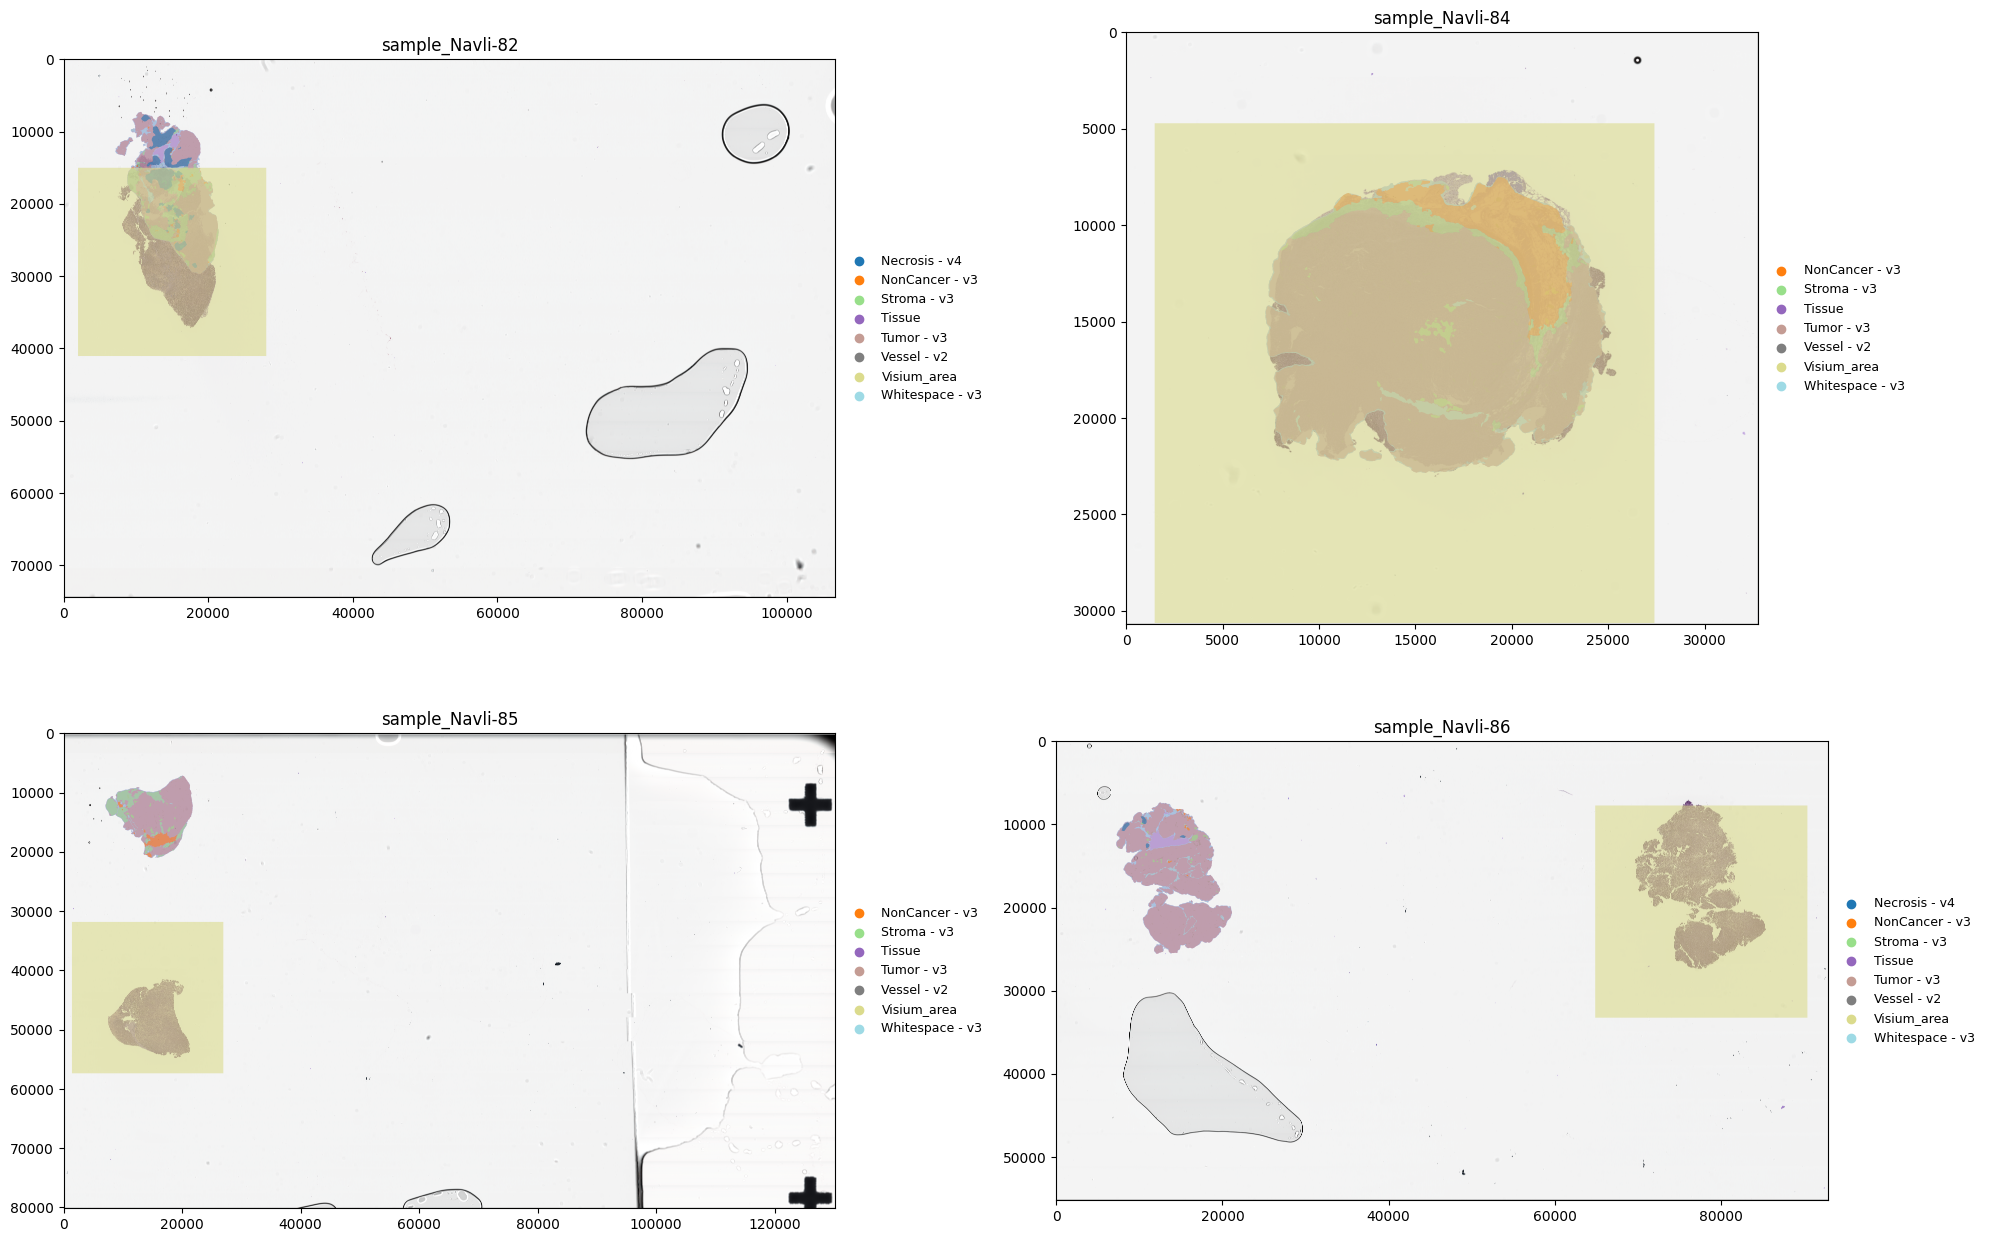

In [12]:
#preview plot for spatialdata object across all annotation classes
axes = plt.subplots(2, 2, figsize=(20, 13), dpi= 300)[1].flatten()
#preview shapes imported 
cmap = matplotlib.cm.get_cmap("tab20", len(all_cats))  # pick e.g. 'tab20', 'tab20b', 'tab20c', 'hsv'
palette_list = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(all_cats))]
#palette_list = pd.Series(palette_list, index=cats)
#['sample_BM0164135A_s1_A1', 'sample_BM0164126_s1_D1', 'sample_BM0164124A_s1_A1', 'sample_BM0164117_s1_D1']
#sample_Navli-82
sdata = sdata_ls['sample_Navli-82']
ax = (
    sdata.pl
        .render_images("Navli-82_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[0],
    title="sample_Navli-82",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-84
sdata = sdata_ls['sample_Navli-84']
ax = (
    sdata.pl
        .render_images("Navli-84_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[1],
    title="sample_Navli-84",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-85
sdata = sdata_ls['sample_Navli-85']
ax = (
    sdata.pl
        .render_images("Navli-85_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[2],
    title="sample_Navli-85",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_Navli-86
sdata = sdata_ls['sample_Navli-86']
ax = (
    sdata.pl
        .render_images("Navli-86_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=all_cats,          # legend/category order
            palette=palette_list,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[3],
    title="sample_Navli-86",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
plt.tight_layout()
del sdata

In [ ]:
#finished until here on Sep 01 2026

In [ ]:
annotation_names = ["Tissue", "Anthropotic", "Necrosis"]

for key, s in sdata_ls.items():
    s = assign_annotations_fast(
        s,
        annotation_names=annotation_names,
        annot_shapes_key="annotations_raw",   # change if your shapes key is different
        table_key="square_002um",
        visium_name="Visium_area",            # or leave as default
        target_coordinate_system="global",
        store_as="bool"                       # or "category" to match your earlier columns
    )
    sdata_ls[key] = s 

In [66]:
#load FucGM1 protein binary data
fucgm1binary_ls = []
for sample_name in sample_names:
    report01 = "Now we are loading binary for: " + sample_name
    img_path = "NSCLC-ADC_" + sample_name + "_coreg_FucGM1_DAB_v1_4x_dwn.tif"
    img_path = os.path.join(fucgm1binaryfiles, img_path)
    print(report01)
    bi_image = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
    #parse FucGM1 protein binary image for spatialdata object
    bi_image = np.expand_dims(bi_image, axis=-1)
    fucgm1binary_ls.append(bi_image)
fucgm1binary_ls = dict(zip(s_names, fucgm1binary_ls))
del bi_image

Now we are loading binary for: BM0164117_s1_D1
Now we are loading binary for: BM0164124A_s1_A1
Now we are loading binary for: BM0164126_s1_D1
Now we are loading binary for: BM0164135A_s1_A1


In [69]:
#calculate real scale factor and store binary image to the spatialdata object
for sample_name in sample_names:
    s_name = "sample_" + sample_name
    bi_image = fucgm1binary_ls[s_name]
    fucgm1_sdname = sample_name + "_FuGM1_4xdown"
    report1 = "Now we are processing " + s_name
    print(report1)
    ##get size of the originial image from the global coordinate system
    global_extent = sd.get_extent(sdata_ls[s_name], coordinate_system='global')
    report2 = "The coordinate of the original image is: " + \
    global_extent['y'][1].astype("str") + " by " + global_extent['x'][1].astype("str")
    print(report2)
    ##calculate real scale factor 
    global_y_size = global_extent['y'][1] - global_extent['y'][0]
    global_x_size = global_extent['x'][1] - global_extent['x'][0]
    report3 = "The size of the original image is: " + global_x_size.astype("str") + ", " + global_y_size.astype("str")
    print(report3)
    #calculate real scale factor for spatialdata object
    bi_image_y_size, bi_image_x_size, channel = bi_image.shape
    scale_factor_y = global_y_size / bi_image_y_size
    scale_factor_x = global_x_size / bi_image_x_size
    scale_factor = [scale_factor_y, scale_factor_x, 1]
    report4 = "The scale factor of " + sample_name + " FucGM1 protein binary is " + \
    " y: " + scale_factor[0].astype("str") + " x: "  + scale_factor[1].astype("str")
    print(report4)
    #scale the 'x', 'y' axis by calculated scale factors
    scale_transformation = Scale(scale_factor, axes=("y", "x", "c"))
    bi_image = Image2DModel.parse(
        bi_image, 
        dims=('y', 'x', 'c'),  # Specify dimensions
        transformations={"global": scale_transformation} # Apply transformation to a new coordinate system "scaled_space"
    )
    sdata_ls[s_name].images[fucgm1_sdname] = bi_image
del bi_image

Now we are processing sample_BM0164117_s1_D1
The coordinate of the original image is: 53259.0 by 73900.0
The size of the original image is: 73903.0, 53262.0
The scale factor of BM0164117_s1_D1 FucGM1 protein binary is  y: 3.7981886900092703 x: 3.980984701572937
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
Now we are processing sample_BM0164124A_s1_A1
The coordinate of the original image is: 55879.0 by 82791.0
The size of the original image is: 82794.0, 55883.0
The scale factor of BM0164124A_s1_A1 FucGM1 protein binary is  y: 3.9856643606019544 x: 3.953113063407181
INFO     Transposing `data` of type: <class 'dask.array.core.Array'> to ('c', 'y', 'x').                           
Now we are processing sample_BM0164126_s1_D1
The coordinate of the original image is: 56083.0 by 83776.0
The size of the original image is: 83779.0, 56086.0
The scale factor of BM0164126_s1_D1 FucGM1 protein binary is  y: 5.139846041055718 x:

In [80]:
#load json files to construct .uns slot
unsinfor_ls = []
for sample_name in sample_names:
    json_path = "Human_NSCLC-ADC_" + sample_name + "/outs/binned_outputs/square_002um/spatial"
    json_path = os.path.join(sourcefiles, json_path, "scalefactors_json.json")
    print(json_path)
    with open(json_path) as json_file:
        data_dict = json.load(json_file)
    unsinfor_ls.append(data_dict)
unsinfor_ls = dict(zip(s_names, unsinfor_ls))

/stash/data/nonclin/TBIO-7810_VisiumHD-FucGM1ADC-NSCLC/source_files/new_batch/Human_NSCLC-ADC_BM0164117_s1_D1/outs/binned_outputs/square_002um/spatial/scalefactors_json.json
/stash/data/nonclin/TBIO-7810_VisiumHD-FucGM1ADC-NSCLC/source_files/new_batch/Human_NSCLC-ADC_BM0164124A_s1_A1/outs/binned_outputs/square_002um/spatial/scalefactors_json.json
/stash/data/nonclin/TBIO-7810_VisiumHD-FucGM1ADC-NSCLC/source_files/new_batch/Human_NSCLC-ADC_BM0164126_s1_D1/outs/binned_outputs/square_002um/spatial/scalefactors_json.json
/stash/data/nonclin/TBIO-7810_VisiumHD-FucGM1ADC-NSCLC/source_files/new_batch/Human_NSCLC-ADC_BM0164135A_s1_A1/outs/binned_outputs/square_002um/spatial/scalefactors_json.json


In [96]:
#construct uns slot
for sample_name in sample_names:
    s_name = "sample_" + sample_name
    #adata = sdata_ls[s_name].tables['square_002um'].copy()
    spot_diameter_hires = unsinfor_ls[s_name]['regist_target_img_scalef']/unsinfor_ls[s_name]['tissue_hires_scalef']
    unsinfor_ls[s_name].update({'spot_diameter_hires': spot_diameter_hires})
    spatial_dic = {sample_name: {'scalefactors' : unsinfor_ls[s_name]}
                  }
    #adata.uns['spatial'] = spatial_dic
    sdata_ls[s_name].tables['square_002um'].uns['spatial'] = spatial_dic
    print(spatial_dic)

{'BM0164117_s1_D1': {'scalefactors': {'spot_diameter_fullres': 7.910568816635662, 'bin_size_um': 2.0, 'microns_per_pixel': 0.2528263196186432, 'tissue_lowres_scalef': 0.008080156, 'fiducial_diameter_fullres': 1305.2438547448844, 'tissue_hires_scalef': 0.080801554, 'regist_target_img_scalef': 0.080801554, 'spot_diameter_hires': 1.0}}}
{'BM0164124A_s1_A1': {'scalefactors': {'spot_diameter_fullres': 7.913288750759672, 'bin_size_um': 2.0, 'microns_per_pixel': 0.2527394188425136, 'tissue_lowres_scalef': 0.007161956, 'fiducial_diameter_fullres': 1305.692643875346, 'tissue_hires_scalef': 0.071619555, 'regist_target_img_scalef': 0.071619555, 'spot_diameter_hires': 1.0}}}
{'BM0164126_s1_D1': {'scalefactors': {'spot_diameter_fullres': 7.911394102082515, 'bin_size_um': 2.0, 'microns_per_pixel': 0.2527999457735951, 'tissue_lowres_scalef': 0.008516921, 'fiducial_diameter_fullres': 1305.380026843615, 'tissue_hires_scalef': 0.0851692, 'regist_target_img_scalef': 0.0851692, 'spot_diameter_hires': 1.0}

In [ ]:
#'quantify' FucGM1 staining
for sample_name in sample_names:
    s_name = "sample_" + sample_name
    fucgm1_sdname = sample_name + "_FuGM1_4xdown"
    features_dic = {'summary': {'quantiles':[1, 0.9, 0.8, 0.7, 0.6
                                             , 0.5, 0.4, 0.3, 0.2, 0.1]
                                }
                    }
    adata = sdata_ls[s_name].tables['square_002um'].copy()
    bi_image = sdata_ls[s_name].images[fucgm1_sdname]
    #calculate scale factor for squidpy image container object
    scale_factor = sum(bi_image.transform['global'].scale[0:2])/2
    scale_factor = 1/scale_factor
    #spot_diameter = 13090/6000 * 1
    adata.uns['spatial'][sample_name]['scalefactors']['tissue_fucgm1_scalef'] = scale_factor
    del adata.uns['spatial'][sample_name]['scalefactors']['spot_diameter_fucgm1']
    bi_image = sq.im.ImageContainer(bi_image, library_id = sample_name
                                    , layer = 'fucgm1', lazy = True
                                    , scale = scale_factor)
    #start quantify now
    sq.im.calculate_image_features(adata, bi_image
                                   , library_id=sample_name
                                   , features='summary'
                                   , key_added='fucgm1summary'
                                   , features_kwargs = features_dic
                                   , layer='fucgm1'
                                   , scale = scale_factor
                                   , n_jobs= 64
                                   , show_progress_bar=True
                                   )
    sdata_ls[s_name].tables['square_002um'] = adata
del adata

  0%|          | 0/11216179 [00:00<?, ?/s]

/home/domino/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/domino/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/domino/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/domino/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/domino/.local

  0%|          | 0/10975965 [00:00<?, ?/s]

/home/domino/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/domino/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/domino/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/domino/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/domino/.local

In [10]:
#update zarr files with annotations
for sample_name in sample_names:
    visiumhd_path = os.path.join(zarrfiles, sample_name)
    visiumhd_path = visiumhd_path + ".zarr"
    sample_name = "sample_" + sample_name
    report = "Now saving: " + sample_name + ".zarr"
    print(report)
    sd.save_transformations(sdata_ls[sample_name])#update files
    #replace_table(sdata_ls[sample_name])
print("All zarr files updated. :)")

Now saving: sample_BM0164117_s1_D1.zarr
Now saving: sample_BM0164124A_s1_A1.zarr
Now saving: sample_BM0164126_s1_D1.zarr
Now saving: sample_BM0164135A_s1_A1.zarr
All zarr files updated. :)


In [ ]:
#preview plot for spatialdata object across only annotation classes of interest
axes = plt.subplots(2, 2, figsize=(20, 13), dpi= 300)[1].flatten()
#preview shapes imported 
#cmap = matplotlib.cm.get_cmap("tab20", len(all_cats))  # pick e.g. 'tab20', 'tab20b', 'tab20c', 'hsv'
#palette_list = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(all_cats))]
indices = [0, 3, 5]#get only relevant colors
palette_list1 = [palette_list[i] for i in indices]
#['sample_BM0164135A_s1_A1', 'sample_BM0164126_s1_D1', 'sample_BM0164124A_s1_A1', 'sample_BM0164117_s1_D1']
annotation_names = ["Anthropotic", "Necrosis", "Tissue"] #annotation of interest
#sample_BM0164135A_s1_A1
sdata = sdata_ls['sample_BM0164135A_s1_A1']
ax = (
    sdata.pl
        .render_images("BM0164135A_s1_A1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list1,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[0],
    title="sample_BM0164135A_s1_A1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164126_s1_D1
sdata = sdata_ls['sample_BM0164126_s1_D1']
ax = (
    sdata.pl
        .render_images("BM0164126_s1_D1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list1,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[1],
    title="sample_BM0164126_s1_D1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164124A_s1_A1
sdata = sdata_ls['sample_BM0164124A_s1_A1']
ax = (
    sdata.pl
        .render_images("BM0164124A_s1_A1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list1,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[2],
    title="sample_BM0164124A_s1_A1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164117_s1_D1
sdata = sdata_ls['sample_BM0164117_s1_D1']
ax = (
    sdata.pl
        .render_images("BM0164117_s1_D1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list1,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[3],
    title="sample_BM0164117_s1_D1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
plt.tight_layout()
del sdata

In [ ]:
#preview plot for spatialdata object across only annotation classes of interest
axes = plt.subplots(2, 2, figsize=(20, 13), dpi= 300)[1].flatten()
#preview shapes imported 
#cmap = matplotlib.cm.get_cmap("tab20", len(all_cats))  # pick e.g. 'tab20', 'tab20b', 'tab20c', 'hsv'
#palette_list = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(all_cats))]
indices = [0, 3, 5, 15]#get only relevant colors
palette_list2 = [palette_list[i] for i in indices]
#['sample_BM0164135A_s1_A1', 'sample_BM0164126_s1_D1', 'sample_BM0164124A_s1_A1', 'sample_BM0164117_s1_D1']
annotation_names = ["Anthropotic", "Necrosis", "Tissue", "Visium_area"] #annotation of interest
#sample_BM0164135A_s1_A1
sdata = sdata_ls['sample_BM0164135A_s1_A1']
ax = (
    sdata.pl
        .render_images("BM0164135A_s1_A1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[0],
    title="sample_BM0164135A_s1_A1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164126_s1_D1
sdata = sdata_ls['sample_BM0164126_s1_D1']
ax = (
    sdata.pl
        .render_images("BM0164126_s1_D1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[1],
    title="sample_BM0164126_s1_D1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164124A_s1_A1
sdata = sdata_ls['sample_BM0164124A_s1_A1']
ax = (
    sdata.pl
        .render_images("BM0164124A_s1_A1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[2],
    title="sample_BM0164124A_s1_A1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164117_s1_D1
sdata = sdata_ls['sample_BM0164117_s1_D1']
ax = (
    sdata.pl
        .render_images("BM0164117_s1_D1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[3],
    title="sample_BM0164117_s1_D1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
plt.tight_layout()
del sdata

In [46]:
#
annotation_names = ["Tissue", "Anthropotic", "Necrosis"]

for key, s in sdata_ls.items():
    s = assign_annotations_fast(
        s,
        annotation_names=annotation_names,
        annot_shapes_key="annotations_raw",
        table_key="square_002um",
        visium_name="Visium_area",
        target_coordinate_system="global",
        store_as="bool",
        show_progress=True,
    )s
    sdata_ls[key] = s

[warn] Element is missing transform to 'global'. Available: ['BM0164117_s1_D1', 'BM0164117_s1_D1_downscaled_hires', 'BM0164117_s1_D1_downscaled_lowres']. Setting Identity() to 'global' (assumes element coords are already in 'global').


Assigning polygons → bins:   0%|          | 0/3 [00:00<?, ?class/s]

{'is_Tissue': 11216179, 'is_Anthropotic': 23671, 'is_Necrosis': 826282}
[warn] Element is missing transform to 'global'. Available: ['BM0164124A_s1_A1', 'BM0164124A_s1_A1_downscaled_hires', 'BM0164124A_s1_A1_downscaled_lowres']. Setting Identity() to 'global' (assumes element coords are already in 'global').


Assigning polygons → bins:   0%|          | 0/3 [00:00<?, ?class/s]

{'is_Tissue': 11209218, 'is_Anthropotic': 52179, 'is_Necrosis': 1598940}
[warn] Element is missing transform to 'global'. Available: ['BM0164126_s1_D1', 'BM0164126_s1_D1_downscaled_hires', 'BM0164126_s1_D1_downscaled_lowres']. Setting Identity() to 'global' (assumes element coords are already in 'global').


Assigning polygons → bins:   0%|          | 0/3 [00:00<?, ?class/s]

{'is_Tissue': 7422314, 'is_Anthropotic': 52550, 'is_Necrosis': 51699}
[warn] Element is missing transform to 'global'. Available: ['BM0164135A_s1_A1', 'BM0164135A_s1_A1_downscaled_hires', 'BM0164135A_s1_A1_downscaled_lowres']. Setting Identity() to 'global' (assumes element coords are already in 'global').


Assigning polygons → bins:   0%|          | 0/3 [00:00<?, ?class/s]

{'is_Tissue': 10965840, 'is_Anthropotic': 127725, 'is_Necrosis': 220992}


In [48]:
#gether all tumor-stroma annotations orgnaized in sample names
# 1007069.annotations == BM0164135A_s1_A1
# 1007068.annotations == BM0164126_s1_D1
# 1007066.annotations == BM0164124A_s1_A1
# 1007067.annotations == BM0164117_s1_D1
new_annotations = ['1007069.annotations', '1007068.annotations'
                   , '1007066.annotations', '1007067.annotations']
new_annotations = dict(zip(s_names, new_annotations))

In [56]:
#load a new annotations and sign to the corresponding spatialdata object
for s_name in s_names:
    annotation_path = new_annotations[s_name]
    annotation_path = os.path.join(newannotation_npath, annotation_path)
    annots_gdf_raw = read_imagescope_annotation_xml(annotation_path)#load files
    annots_gdf_raw = ShapesModel.parse(annots_gdf_raw)
    sdata_ls[s_name].shapes["tumor_stromal.annotation"] = annots_gdf_raw
    #sdata_ls[s_name].delete_element_from_disk('annotations_raw')
    #by the way rename old annotations
    sdata_ls[s_name].shapes['qc.annotation'] = sdata_ls[s_name].shapes['annotations_raw']
    del sdata_ls[s_name].shapes['annotations_raw']

In [ ]:
#convert to annotations
annotation_names = ["Stroma_v4", "Tumor_v4", "WhiteSpace_v4"]
for s_name in s_names:
    sdata_ls[s_name] = assign_annotations_fast(
        sdata_ls[s_name],
        annotation_names=annotation_names,
        annot_shapes_key="tumor_stromal.annotation",   # change if your shapes key is different
        table_key="square_002um",
        visium_name="Visium_area",            # or leave as default
        target_coordinate_system="global",
        store_as='bool'                      # or "category" to match your earlier columns
    )

Assigning polygons → bins:   0%|          | 0/3 [00:00<?, ?class/s]

In [88]:
#update the .zarr file on disk for all the slots that were changed 
for key, s in sdata_ls.items():
    report_info = "Now we are working on spatialdata: " + key
    print(report_info)
    persist_changes(
        s,
        update_elements=["square_002um"],
        new_elements=["annotations_clean", "qc.annotation", 'tumor_stromal.annotation'],
        update_transformations=True,
        consolidate_metadata=True,
    )

Now we are working on spatialdata: sample_BM0164117_s1_D1
Now updating square_002um on disk.
Now creating new data record for annotations_clean on disk.
Now creating new data record for qc.annotation on disk.
Now creating new data record for tumor_stromal.annotation on disk.
Now we are working on spatialdata: sample_BM0164124A_s1_A1
Now updating square_002um on disk.
Now creating new data record for annotations_clean on disk.
Now creating new data record for qc.annotation on disk.
Now creating new data record for tumor_stromal.annotation on disk.
Now we are working on spatialdata: sample_BM0164126_s1_D1
Now updating square_002um on disk.
Now creating new data record for annotations_clean on disk.
Now creating new data record for qc.annotation on disk.
Now creating new data record for tumor_stromal.annotation on disk.
Now we are working on spatialdata: sample_BM0164135A_s1_A1
Now updating square_002um on disk.
Now creating new data record for annotations_clean on disk.
Now creating new 

In [ ]:
#examine signal distribution over transcript, image features and tissue masks
sc.set_figure_params(dpi = 300, dpi_save = 450, figsize = (5, 5.5))
adata = sdata_ls['sample_BM0164135A_s1_A1'].tables['square_002um']
#calculate qc metircs for transcript level plots
sc.pp.calculate_qc_metrics(adata, percent_top=(50, 100, 200, 500), inplace=True)
feats = ["summary_ch-0_quantile-0.8", "summary_ch-1_quantile-0.8", "summary_ch-2_quantile-0.8"]
adata.obs[feats] = adata.obsm['normsummary'][feats]
adata.obs['is_Tissue'] = adata.obs['is_Tissue'].astype('category')
adata.obs['is_Anthropotic'] = adata.obs['is_Anthropotic'].astype('category')
adata.obs['is_Necrosis'] = adata.obs['is_Necrosis'].astype('category')
feats.append("log1p_total_counts")
feats.append("in_tissue")
feats.append("is_Tissue")
feats.append("is_Anthropotic")
feats.append("is_Necrosis")
print(feats)
#
sc.pl.embedding(adata
                , basis="spatial", size=0.5, ncols = 2
                , color = feats
                )

In [ ]:
#preview plot for all samples
axes = plt.subplots(2, 2, figsize=(20, 20), dpi= 300)[1].flatten()
#sdata.pl.render_images("he_image").pl.show(ax=axes[0], title="H&E image")
sdata_ls['sample_BM0164135A_s1_A1'].pl.render_images("BM0164135A_s1_A1_FuGM1_4xdown").pl.show(ax=axes[0], title='BM0164135A_s1_A1')
sdata_ls['sample_BM0164117_s1_D1'].pl.render_images("BM0164117_s1_D1_FuGM1_4xdown").pl.show(ax=axes[1], title='BM0164117_s1_D1')
sdata_ls['sample_BM0164126_s1_D1'].pl.render_images("BM0164126_s1_D1_FuGM1_4xdown").pl.show(ax=axes[2], title='BM0164126_s1_D1')
sdata_ls['sample_BM0164124A_s1_A1'].pl.render_images("BM0164124A_s1_A1_FuGM1_4xdown").pl.show(ax=axes[3], title='BM0164124A_s1_A1')

In [ ]:
#confirm annotation locations
sc.set_figure_params(dpi = 300, dpi_save = 450, figsize = (5, 5))
sdata_ls['sample_BM0164135A_s1_A1'].tables["square_002um"].obs['is_Tissue'] = \
sdata_ls['sample_BM0164135A_s1_A1'].tables["square_002um"].obs['is_Tissue'].astype('category')

sdata_ls['sample_BM0164135A_s1_A1'].tables["square_002um"].obs['is_Anthropotic'] = \
sdata_ls['sample_BM0164135A_s1_A1'].tables["square_002um"].obs['is_Anthropotic'].astype('category')

sdata_ls['sample_BM0164135A_s1_A1'].tables["square_002um"].obs['is_Necrosis'] = \
sdata_ls['sample_BM0164135A_s1_A1'].tables["square_002um"].obs['is_Necrosis'].astype('category')

sc.pl.embedding(sdata_ls['sample_BM0164135A_s1_A1'].tables["square_002um"]
                , basis="spatial", color = ['is_Tissue', 'is_Anthropotic', 'is_Necrosis']
                , size=0.5, ncols = 3)

In [ ]:
#confirm annotation locations
sdata_ls['sample_BM0164126_s1_D1'].tables["square_002um"].obs['is_Tissue'] = \
sdata_ls['sample_BM0164126_s1_D1'].tables["square_002um"].obs['is_Tissue'].astype('category')

sdata_ls['sample_BM0164126_s1_D1'].tables["square_002um"].obs['is_Anthropotic'] = \
sdata_ls['sample_BM0164126_s1_D1'].tables["square_002um"].obs['is_Anthropotic'].astype('category')

sdata_ls['sample_BM0164126_s1_D1'].tables["square_002um"].obs['is_Necrosis'] = \
sdata_ls['sample_BM0164126_s1_D1'].tables["square_002um"].obs['is_Necrosis'].astype('category')
sc.pl.embedding(sdata_ls['sample_BM0164126_s1_D1'].tables["square_002um"]
                , basis="spatial", color = ['is_Tissue', 'is_Anthropotic', 'is_Necrosis']
                , size=0.5, ncols = 3)

In [ ]:
#confirm annotation locations
sdata_ls['sample_BM0164124A_s1_A1'].tables["square_002um"].obs['is_Tissue'] = \
sdata_ls['sample_BM0164124A_s1_A1'].tables["square_002um"].obs['is_Tissue'].astype('category')

sdata_ls['sample_BM0164124A_s1_A1'].tables["square_002um"].obs['is_Anthropotic'] = \
sdata_ls['sample_BM0164124A_s1_A1'].tables["square_002um"].obs['is_Anthropotic'].astype('category')

sdata_ls['sample_BM0164124A_s1_A1'].tables["square_002um"].obs['is_Necrosis'] = \
sdata_ls['sample_BM0164124A_s1_A1'].tables["square_002um"].obs['is_Necrosis'].astype('category')
sc.pl.embedding(sdata_ls['sample_BM0164124A_s1_A1'].tables["square_002um"]
                , basis="spatial", color = ['is_Tissue', 'is_Anthropotic', 'is_Necrosis']
                , size=0.5, ncols = 3)

In [ ]:
#confirm annotation locations
sdata_ls['sample_BM0164117_s1_D1'].tables["square_002um"].obs['is_Tissue'] = \
sdata_ls['sample_BM0164117_s1_D1'].tables["square_002um"].obs['is_Tissue'].astype('category')

sdata_ls['sample_BM0164117_s1_D1'].tables["square_002um"].obs['is_Anthropotic'] = \
sdata_ls['sample_BM0164117_s1_D1'].tables["square_002um"].obs['is_Anthropotic'].astype('category')

sdata_ls['sample_BM0164117_s1_D1'].tables["square_002um"].obs['is_Necrosis'] = \
sdata_ls['sample_BM0164117_s1_D1'].tables["square_002um"].obs['is_Necrosis'].astype('category')
sc.pl.embedding(sdata_ls['sample_BM0164117_s1_D1'].tables["square_002um"]
                , basis="spatial", color = ['is_Tissue', 'is_Anthropotic', 'is_Necrosis']
                , size=0.5, ncols = 3)

In [ ]:
#update the .zarr file on disk for all the slots that were changed 
for key, s in sdata_ls.items():
    report_info = "Now we are working on spatialdata: " + key
    print(report_info)
    persist_changes(
        s,
        update_elements=["square_002um"],
        #new_elements=["annotations_raw", "annotations_clean"],
        update_transformations=True,
        consolidate_metadata=True,
    )

Now we are working on spatialdata: sample_BM0164135A_s1_A1
Now updating square_002um on disk.
No new element will be recored.
Now we are working on spatialdata: sample_BM0164126_s1_D1
Now updating square_002um on disk.
No new element will be recored.
Now we are working on spatialdata: sample_BM0164124A_s1_A1
Now updating square_002um on disk.
No new element will be recored.
Now we are working on spatialdata: sample_BM0164117_s1_D1
Now updating square_002um on disk.
No new element will be recored.


In [ ]:
#print environment and packages used
%watermark -d -i -m -iv -v --gpu

In [ ]:
#preview plot for spatialdata object across only annotation classes of interest
axes = plt.subplots(2, 2, figsize=(20, 13), dpi= 300)[1].flatten()
#preview shapes imported 
#cmap = matplotlib.cm.get_cmap("tab20", len(all_cats))  # pick e.g. 'tab20', 'tab20b', 'tab20c', 'hsv'
#palette_list = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(all_cats))]
indices = [0, 3, 5, 15]#get only relevant colors
palette_list2 = [palette_list[i] for i in indices]
#['sample_BM0164135A_s1_A1', 'sample_BM0164126_s1_D1', 'sample_BM0164124A_s1_A1', 'sample_BM0164117_s1_D1']
annotation_names = ["Anthropotic", "Necrosis", "Tissue", "Visium_area"] #annotation of interest
#sample_BM0164135A_s1_A1
sdata = sdata_ls['sample_BM0164135A_s1_A1']
ax = (
    sdata.pl
        .render_images("BM0164135A_s1_A1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[0],
    title="sample_BM0164135A_s1_A1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164126_s1_D1
sdata = sdata_ls['sample_BM0164126_s1_D1']
ax = (
    sdata.pl
        .render_images("BM0164126_s1_D1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[1],
    title="sample_BM0164126_s1_D1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164124A_s1_A1
sdata = sdata_ls['sample_BM0164124A_s1_A1']
ax = (
    sdata.pl
        .render_images("BM0164124A_s1_A1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[2],
    title="sample_BM0164124A_s1_A1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
#sample_BM0164117_s1_D1
sdata = sdata_ls['sample_BM0164117_s1_D1']
ax = (
    sdata.pl
        .render_images("BM0164117_s1_D1_hires_image")          # your image key
        .pl.render_shapes(
            "annotations_clean",
            color="name",            # now categorical
            groups=annotation_names,          # legend/category order
            palette=palette_list2,       # one color per category (aligned with `groups`)
            method="matplotlib",        # enables legend for categorical colors
            fill_alpha=0.6,
            outline=True,
            outline_width=0.5,
            outline_color="#000000",
        )
)
ax.pl.show(
    ax=axes[3],
    title="sample_BM0164117_s1_D1",
    coordinate_systems="global",
    legend_loc="right margin",          # or 'upper right', 'lower left', etc.
    legend_fontsize=9,
    colorbar=False    
)
plt.tight_layout()
del sdata